# Задание 1. Детектор мошеннических транзакций

## 1. Бизнес-постановка задачи

**Проблема.** Банк обрабатывает сотни тысяч транзакций в сутки. Мошеннические операции составляют доли процента, но каждая из них — это прямые финансовые потери и репутационный ущерб. Ручная проверка всех операций невозможна из-за объема.


**Цель.** Автоматически выявлять подозрительные транзакции, чтобы блокировать мошенничество до списания средств.

**Бизнес-эффект.** Снижение потерь от мошенничества, уменьшение нагрузки на службу фрод-мониторинга, повышение доверия клиентов.

**Стоимость ошибок:**
* **False Positive (FP):** нормальная транзакция помечена как мошенническая. Клиент не может оплатить покупку, банк несёт репутационные издержки.
* **False Negative (FN):** мошенническая транзакция пропущена. Банк теряет деньги.

**Вывод:** Модель должна выдавать вероятность мошенничества, чтобы банк мог настроить порог срабатывания под свою политику риск-менеджмента.

## 2. ML-постановка задачи

- **Тип задачи:** бинарная классификация.
- **Целевая переменная:** Class (0 — легитимная транзакция, 1 — мошенническая).
- **Входные признаки:** 30 числовых признаков: Time, Amount, V1–V28 (результат PCA-преобразования исходных данных банка для анонимизации).
- **Особенность:** экстремальный дисбаланс классов — мошенничество составляет ~0.172% всех наблюдений.

## 3. Набор данных

**Источник:** [Kaggle — Credit Card Fraud Detection (ULB Machine Learning Group)](https://www.kaggle.com/mlg-ulb/creditcardfraud)

| Параметр | Значение |
|---|---|
| Всего транзакций | 284 807 |
| Мошеннических | 492 |
| Легитимных | 284 315 |
| Признаков | 31 (включая целевой) |
| Пропуски | отсутствуют |
| Период сбора | 2 дня (сентябрь 2013, Европа) |

Признаки V1–V28 уже прошли PCA и не поддаются прямой интерпретации; Time — секунды с первой транзакции; Amount — сумма транзакции.

**Достаточность данных.** 284 807 объектов и 30 признаков достаточно для обучения и честной оценки моделей. Ограничения: положительных примеров всего 492 (нужна стратификация и аккуратная валидация), признаки анонимизированы (нет бизнес-интерпретации), период наблюдений — только 2 дня.

## 4. Метрики качества и их обоснование

### Выбранные метрики

1. **PR-AUC (Area Under Precision-Recall Curve)** — основная метрика для сравнения моделей.
2. **Recall, Precision и F2-score** — для оценки качества при выбранном пороге (F2 даёт Recall вдвое больший вес, чем Precision).
3. **ROC-AUC** — только справочно.

### Обоснование

Основная метрика — **PR-AUC**: при доле мошенничества 0.17% accuracy бессмысленна (модель «всё легитимно» даёт ~99.83%), а PR-кривая оценивает качество именно на редком положительном классе и не завышается огромным числом истинно отрицательных объектов, в отличие от ROC-AUC. Порог срабатывания подбираем по **Recall и F2**, поскольку пропуск мошенничества (FN) обычно дороже ложной тревоги (FP); конкретный порог банк выбирает исходя из стоимости ошибок обоих типов.

In [ ]:
!pip install kaggle --quiet

from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Скачиваем и сразу распаковываем в текущую папку
!kaggle datasets download -d mlg-ulb/creditcardfraud -p /content --unzip

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 102MB/s]



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("creditcard.csv")

print("Размер датасета:", df.shape)
df.head()

Размер датасета: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 5. EDA — разведочный анализ данных

### 5.1. Базовые статистики

In [ ]:
print("Размер датасета:", df.shape)
print("\nТипы данных:")
print(df.dtypes.value_counts())

print("\nПропущенные значения:", df.isnull().sum().sum())
print("Полных дубликатов:", df.duplicated().sum())

print("\nРаспределение целевой переменной:")
print(df["Class"].value_counts())
print(f"\nДоля мошеннических транзакций: {df['Class'].mean()*100:.4f}%")
print("Дисбаланс: 1 к", round((df['Class'] == 0).sum() / (df['Class'] == 1).sum()))

print("\nСтатистика по Amount:")
print(df["Amount"].describe())

print("\nСтатистика по Time:")
print(df["Time"].describe())

Размер датасета: (284807, 31)

Типы данных:
float64    30
int64       1
Name: count, dtype: int64

Пропущенные значения: 0
Полных дубликатов: 1081

Распределение целевой переменной:
Class
0    284315
1       492
Name: count, dtype: int64

Доля мошеннических транзакций: 0.1727%
Дисбаланс: 1 к 578

Статистика по Amount:
count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

Статистика по Time:
count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64


In [ ]:
# Дополнительные базовые проверки: дубликаты и разброс признаков V1–V28
print("Полных дубликатов:", df.duplicated().sum())
print("Из них мошеннических:", int(df[df.duplicated()].Class.sum()))

pca_cols = [f"V{i}" for i in range(1, 29)]

desc = df[pca_cols].agg(["mean", "std"]).T
display(desc.round(3))
print(f"Среднее V1–V28: от {desc['mean'].min():.3f} до {desc['mean'].max():.3f}")
print(f"Std V1–V28:     от {desc['std'].min():.3f} до {desc['std'].max():.3f}")

Полных дубликатов: 1081
Из них мошеннических: 19


,mean,std
V1,0.0,1.959
V2,0.0,1.651
V3,-0.0,1.516
V4,0.0,1.416
V5,0.0,1.380
V6,0.0,1.332
V7,-0.0,1.237
V8,0.0,1.194
V9,-0.0,1.099
V10,0.0,1.089


Среднее V1–V28: от -0.000 до 0.000
Std V1–V28:     от 0.330 до 1.959


**Выводы.**
- Датасет содержит **284 807 строк и 31 столбец** (30 признаков типа float64 и Class типа int64). **Пропусков нет** — импутация не нужна.
- Дисбаланс: 492 мошеннических и 284 315 легитимных транзакций, доля мошенничества **0.1727%**, то есть примерно **1 к 578**.
- **Полных дубликатов 1081**, из них 19 мошеннических (около 4% всех мошеннических операций). Дубликаты нужно удалить **до разбиения** на train/test: иначе одинаковые записи попадут в обе части, и качество будет завышено. После удаления проверяем, сколько объектов каждого класса осталось.
- Amount: среднее 88.35 заметно выше медианы 22.0, std 250, максимум 25 691 — распределение с сильным правым хвостом.
- Time: значения от 0 до 172 792 секунд (≈ 48 часов) — подтверждает, что данные охватывают двое суток.
- V1–V28 (PCA): средние близки к нулю, но стандартные отклонения различаются (см. таблицу выше), то есть признаки **центрированы, но не стандартизированы**. Для линейных моделей и kNN нужен масштабатор, обучаемый только на train-части.

### 5.2. Распределение целевого класса

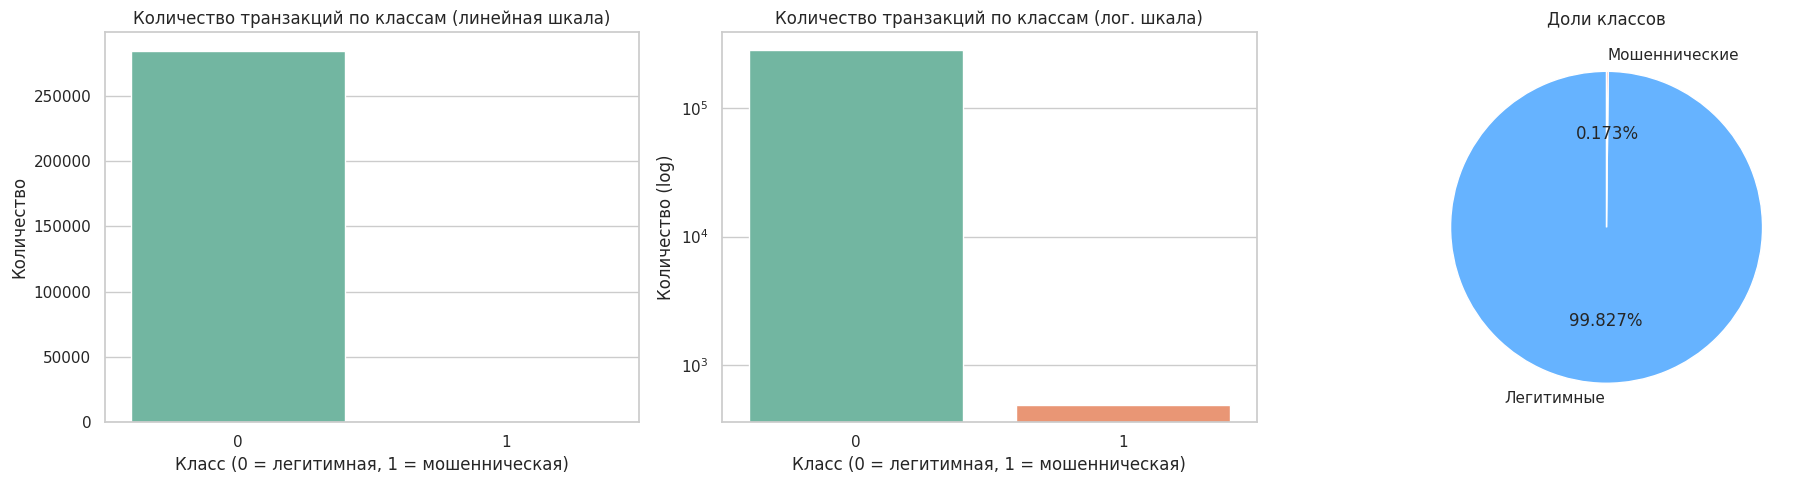

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.countplot(data=df, x="Class", hue="Class", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Количество транзакций по классам (линейная шкала)")
axes[0].set_xlabel("Класс (0 = легитимная, 1 = мошенническая)")
axes[0].set_ylabel("Количество")

sns.countplot(data=df, x="Class", hue="Class", palette="Set2", legend=False, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Количество транзакций по классам (лог. шкала)")
axes[1].set_xlabel("Класс (0 = легитимная, 1 = мошенническая)")
axes[1].set_ylabel("Количество (log)")

class_counts = df["Class"].value_counts()
axes[2].pie(class_counts, labels=["Легитимные", "Мошеннические"],
            autopct="%1.3f%%", colors=["#66b3ff", "#ff6666"], startangle=90)
axes[2].set_title("Доли классов")

plt.tight_layout()
plt.show()

**Вывод.** Мошенничество составляет 0.17%: на линейной шкале столбец класса 1 практически не виден. Следствия:
- accuracy неинформативна, оцениваем по PR-AUC, Recall, Precision, F2;
- разбиение и кросс-валидация должны быть **стратифицированными** (stratify=y, StratifiedKFold);
- модели нужно настраивать с учётом дисбаланса (class_weight, scale_pos_weight, подбор порога);
- SMOTE/undersampling применять **только внутри train-фолдов**, иначе будет утечка.

### 5.3. Анализ временного признака (Time)

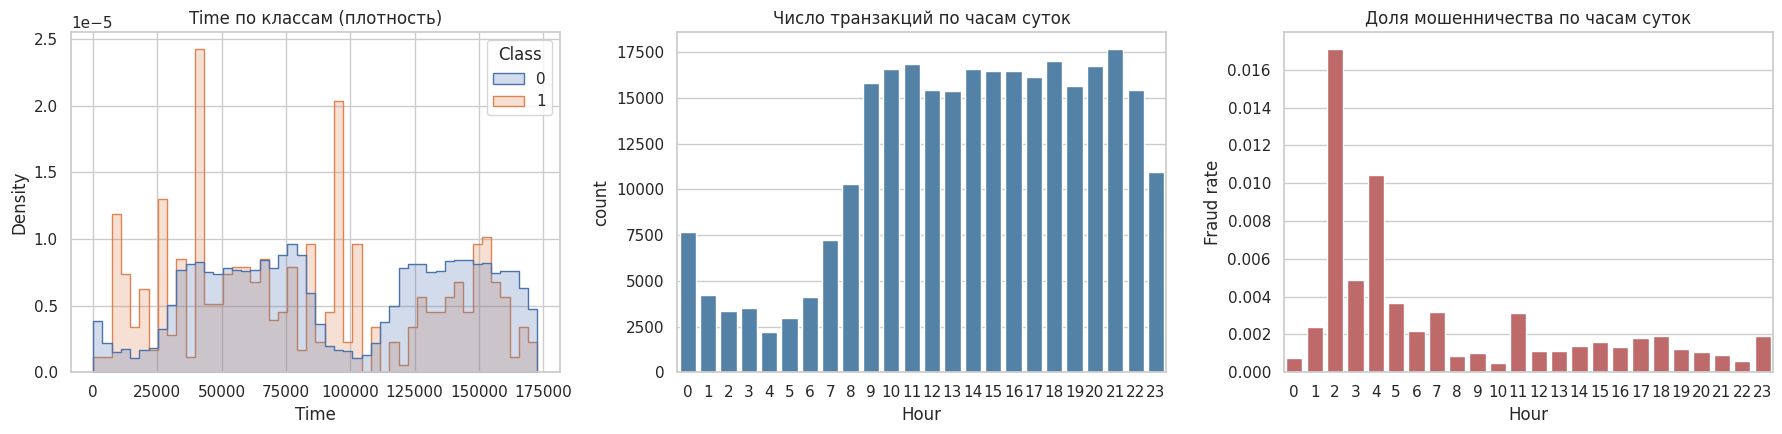

In [ ]:
# Time — секунды с начала наблюдаемого периода.
# Разбиваем время на последовательные интервалы по одному часу.
df["Hour"] = ((df["Time"] // 3600) % 24).astype(int)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

sns.histplot(data=df, x="Time", hue="Class", stat="density", common_norm=False,
             bins=48, element="step", ax=ax[0])
ax[0].set_title("Time по классам (плотность)")

hourly = df.groupby("Hour")["Class"].agg(["count", "sum", "mean"]).reset_index()
sns.barplot(data=hourly, x="Hour", y="count", ax=ax[1], color="steelblue")
ax[1].set_title("Число транзакций по часам суток")

sns.barplot(data=hourly, x="Hour", y="mean", ax=ax[2], color="indianred")
ax[2].set_title("Доля мошенничества по часам суток")
ax[2].set_ylabel("Fraud rate")
plt.tight_layout(); plt.show()

**Выводы:**

- Признак Time отражает количество секунд, прошедших с начала наблюдаемого периода, поэтому его нельзя напрямую интерпретировать как реальное время суток.
- Количество транзакций и доля мошеннических операций различаются между последовательными часовыми интервалами.
- Наблюдаемые различия могут указывать на наличие временных закономерностей, однако их устойчивость необходимо дополнительно проверить, поскольку мошеннические транзакции составляют лишь небольшую часть датасета.


### 5.4. Анализ суммы транзакции (Amount)

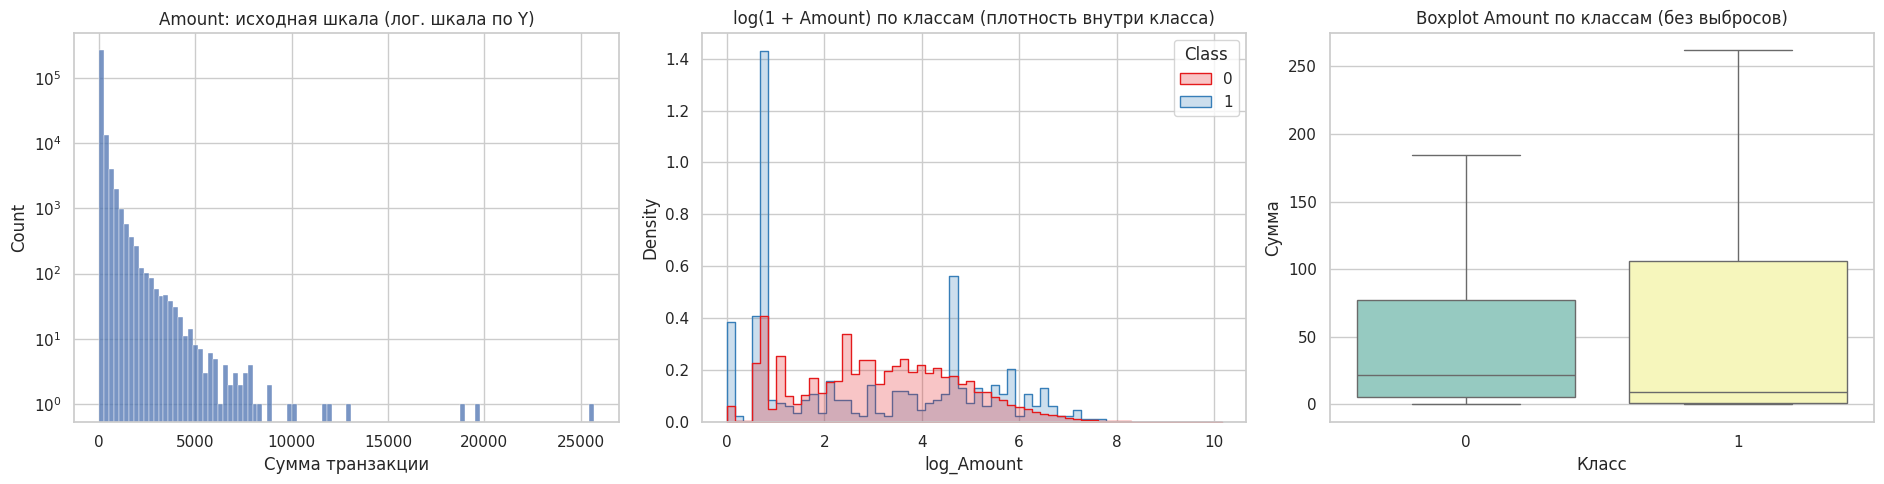

Статистика Amount по классам:
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87

Доля транзакций с Amount == 0: 0.0064
Доля fraud с Amount < 10: 0.506
Доля legit с Amount < 10: 0.341


In [ ]:
df["log_Amount"] = np.log1p(df["Amount"])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.histplot(df["Amount"], bins=100, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Amount: исходная шкала (лог. шкала по Y)")
axes[0].set_xlabel("Сумма транзакции")

sns.histplot(data=df, x="log_Amount", hue="Class", bins=60, stat="density",
             common_norm=False, element="step", palette="Set1", ax=axes[1])
axes[1].set_title("log(1 + Amount) по классам (плотность внутри класса)")

sns.boxplot(data=df, x="Class", y="Amount", hue="Class", palette="Set3", legend=False,
            showfliers=False, ax=axes[2])
axes[2].set_title("Boxplot Amount по классам (без выбросов)")
axes[2].set_xlabel("Класс")
axes[2].set_ylabel("Сумма")

plt.tight_layout()
plt.show()

print("Статистика Amount по классам:")
print(df.groupby("Class")["Amount"].describe())
print("\nДоля транзакций с Amount == 0:", round((df["Amount"] == 0).mean(), 4))
print("Доля fraud с Amount < 10:", round((df.loc[df.Class == 1, "Amount"] < 10).mean(), 3))
print("Доля legit с Amount < 10:", round((df.loc[df.Class == 0, "Amount"] < 10).mean(), 3))

**Вывод.**
- Распределение Amount сильно скошено вправо: среднее 88.35 при медиане 22.0, максимум 25 691. На логарифмической шкале видно длинный хвост из редких крупных операций.
- У мошеннических транзакций медиана **меньше** (9.25 против 22.0 у легитимных), а доля операций до 10 выше (50.6% против 34.1%). Это похоже на «пробные» мелкие списания, которыми проверяют карту.
- При этом максимальная мошенническая сумма (≈ 2 126) намного меньше максимальной легитимной, поэтому крупная сумма сама по себе не признак фрода. Средние значения (122 против 88) различаются слабо из-за хвоста, поэтому сравнивать классы лучше по медиане и распределению log(1 + Amount).
- Операции с нулевой суммой составляют около 0.64% — это вероятные проверочные запросы, их стоит оставить как есть и проверить, как они распределены по классам.
- **Что делаем:** Amount преобразуем (log1p или RobustScaler); выбросы **не удаляем**, поскольку редкие крупные суммы могут быть как легитимными, так и сигналом.

### 5.5. Корреляционный анализ

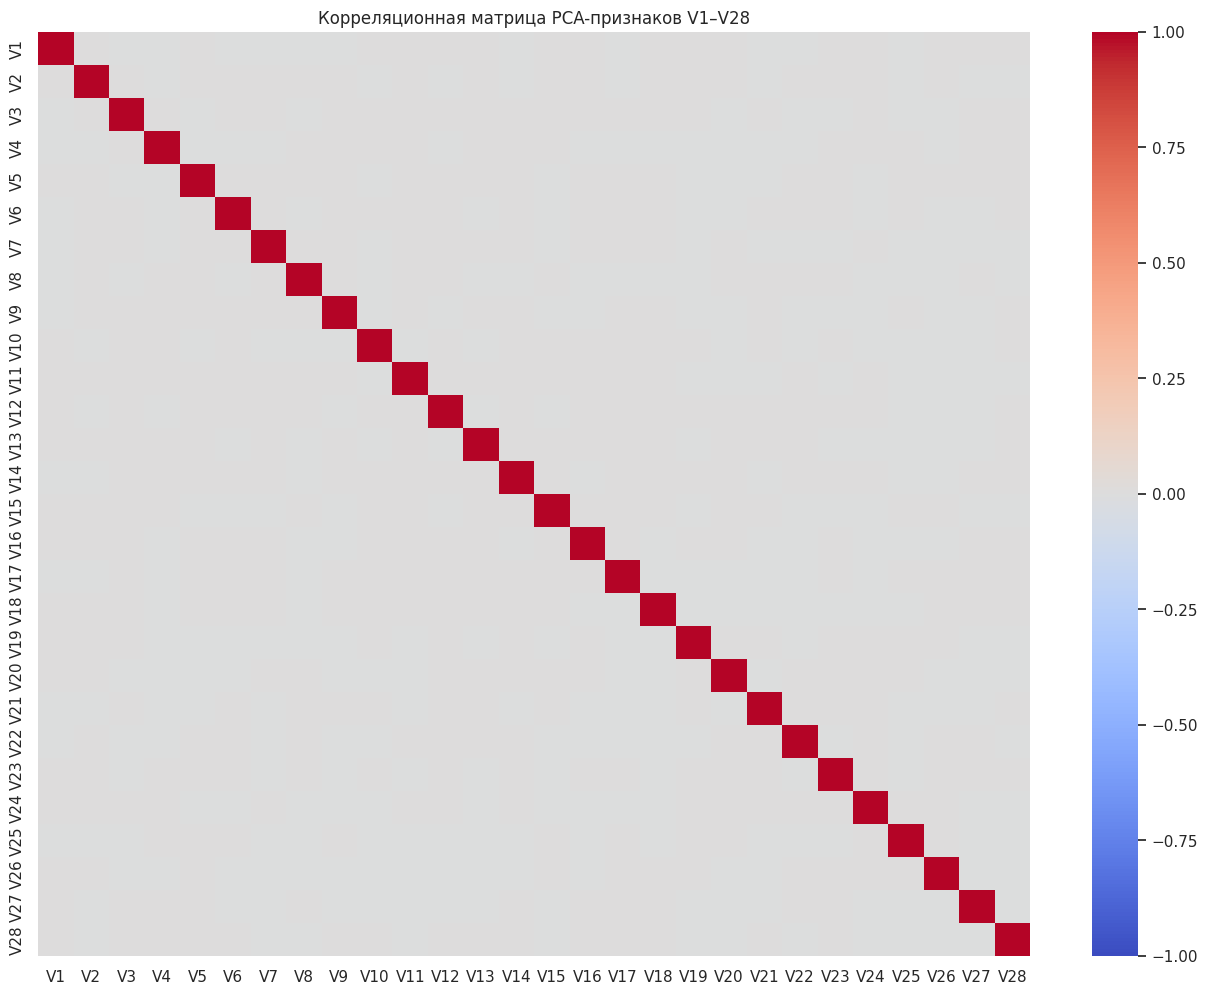

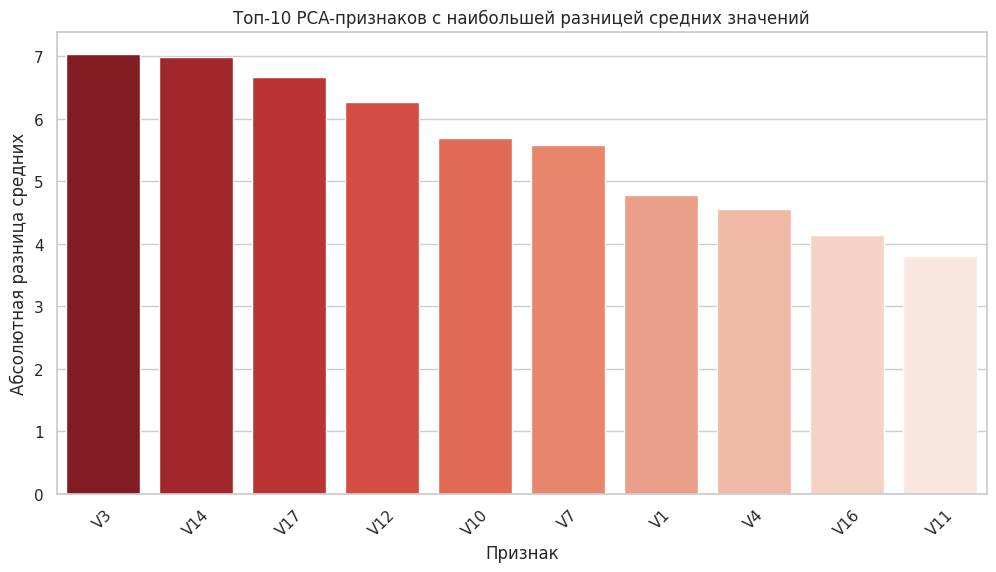

Топ-10 PCA-признаков:
     Легитимные  Мошеннические   Разница
V3     0.012171      -7.033281  7.045452
V14    0.012064      -6.971723  6.983787
V17    0.011535      -6.665836  6.677371
V12    0.010832      -6.259393  6.270225
V10    0.009824      -5.676883  5.686707
V7     0.009637      -5.568731  5.578368
V1     0.008258      -4.771948  4.780206
V4    -0.007860       4.542029  4.549889
V16    0.007164      -4.139946  4.147110
V11   -0.006576       3.800173  3.806749


In [ ]:
pca_cols = [f"V{i}" for i in range(1, 29)]

# Тепловая карта корреляций
plt.figure(figsize=(16, 12))
sns.heatmap(df[pca_cols].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Корреляционная матрица PCA-признаков V1–V28")
plt.show()

# Поиск топ-10 признаков с наибольшей разницей средних
means = df.groupby("Class")[pca_cols].mean().T
means.columns = ["Легитимные", "Мошеннические"]
means["Разница"] = abs(means["Мошеннические"] - means["Легитимные"])
top_features = means.sort_values("Разница", ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_features.index, y=top_features["Разница"], hue=top_features.index, palette="Reds_r", legend=False)
plt.title("Топ-10 PCA-признаков с наибольшей разницей средних значений")
plt.xlabel("Признак")
plt.ylabel("Абсолютная разница средних")
plt.xticks(rotation=45)
plt.show()

print("Топ-10 PCA-признаков:")
print(top_features)

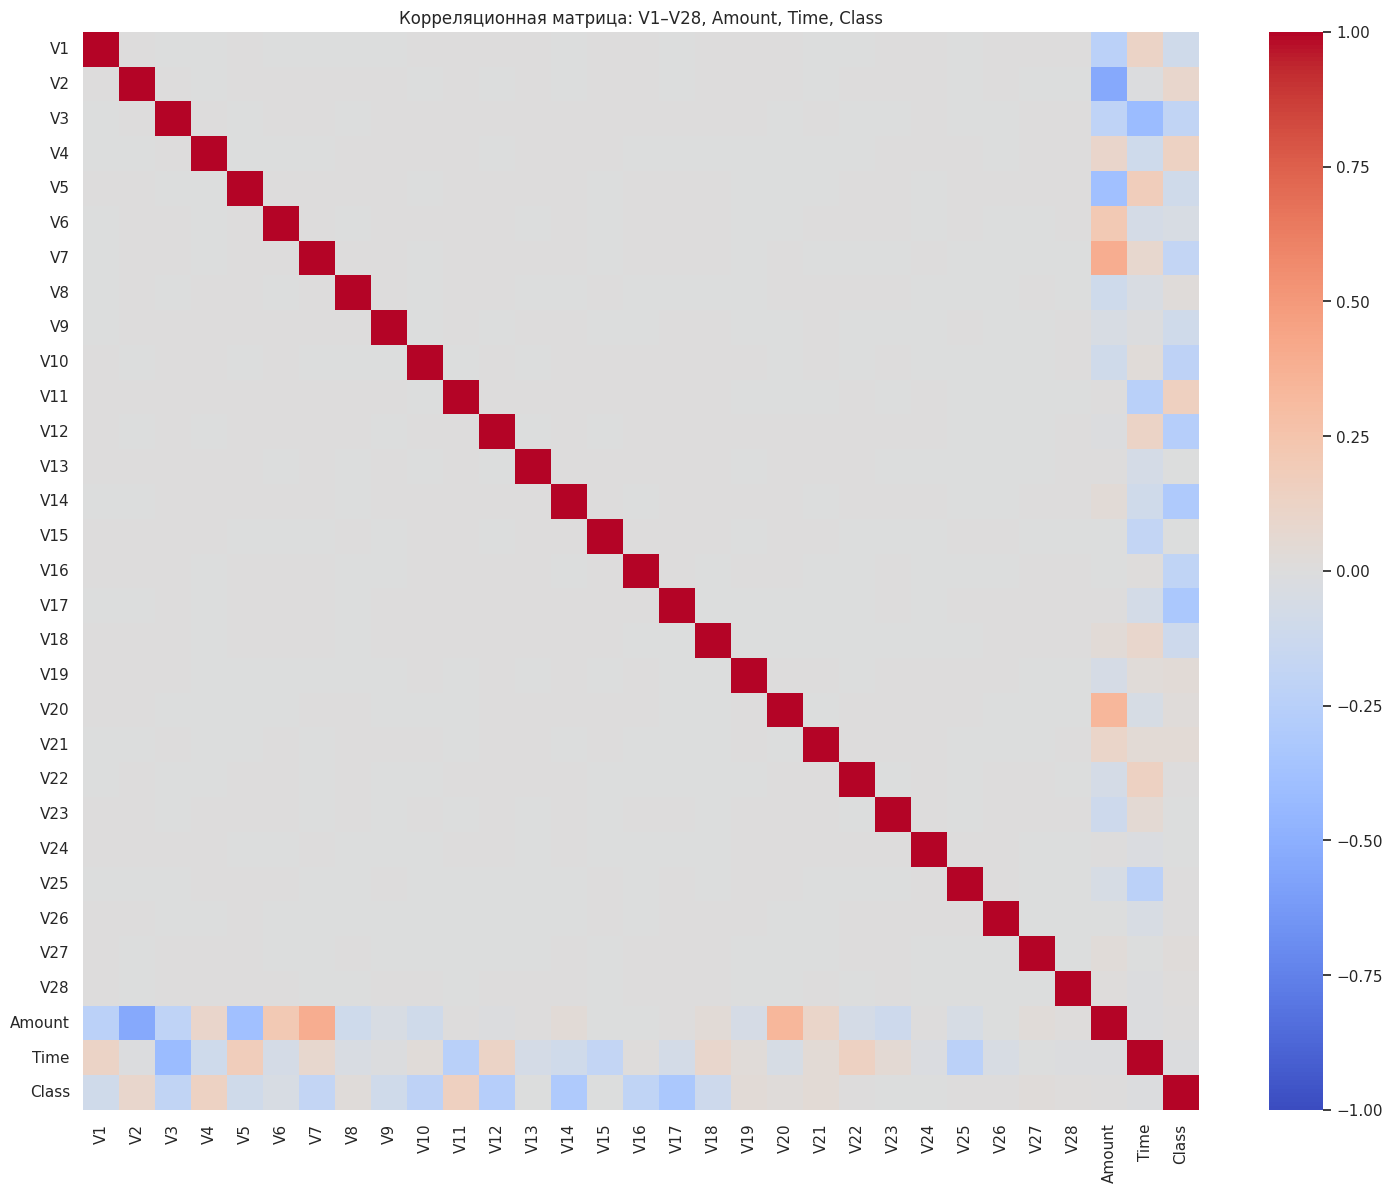

In [ ]:
# Расширенная корреляционная матрица: V1–V28 + Amount, Time и целевой Class
plt.figure(figsize=(18, 14))
sns.heatmap(df[pca_cols + ["Amount", "Time", "Class"]].corr(),
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Корреляционная матрица: V1–V28, Amount, Time, Class")
plt.show()

**Вывод.**
- Компоненты V1–V28 **практически не коррелируют между собой** (следствие PCA): мультиколлинеарности нет.
- По разнице средних между классами лидируют **V3, V14, V17, V12, V10, V7, V1, V4, V16, V11**: у мошенничества средние значения этих признаков сильно сдвинуты относительно легитимных (у V3, V14, V17, V12, V10, V7, V1, V16 — в отрицательную сторону, у V4 и V11 — в положительную).
- Оговорка: сырая разница средних зависит от масштаба признака, поэтому её стоит подтверждать корреляцией с таргетом и распределениями (см. ниже).
- V* анонимизированы, их нельзя интерпретировать в терминах бизнеса; объяснимость возможна только через важность признаков и SHAP.
- На расширенной матрице смотрим на строки/столбцы Amount и Time: они не являются PCA-компонентами, поэтому их корреляции с отдельными V* возможны и не противоречат выводу об ортогональности самих V1–V28. Связь Amount и Time с Class линейно слабая, но это не означает, что признаки бесполезны (см. анализ выше).

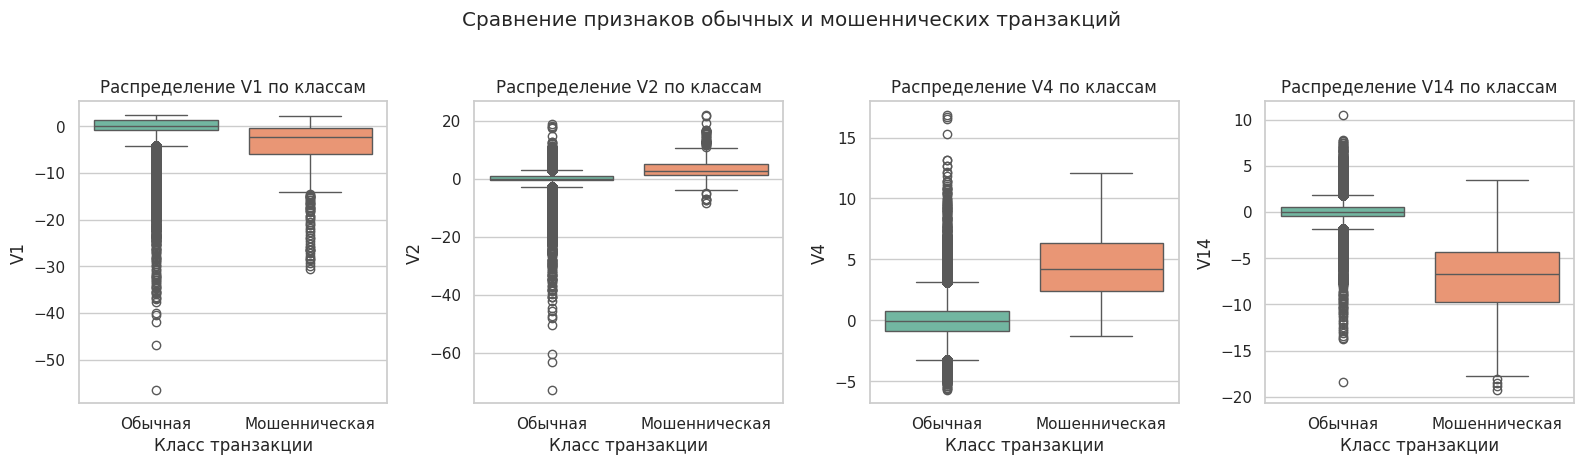

In [ ]:
# Сравнение распределений выбранных признаков по классам
selected_features = ["V1", "V2", "V4", "V14"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

for ax, feat in zip(axes, selected_features):
    sns.boxplot(data=df, x="Class", y=feat, hue="Class", palette="Set2", legend=False, ax=ax)

    ax.set_title(f"Распределение {feat} по классам")
    ax.set_xlabel("Класс транзакции")
    ax.set_ylabel(feat)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Обычная", "Мошенническая"])

plt.suptitle("Сравнение признаков обычных и мошеннических транзакций", y=1.03)
plt.tight_layout()
plt.show()

**Вывод.** Диаграммы размаха позволяют сравнить медианы, разброс и экстремальные значения выбранных PCA-признаков для обычных и мошеннических транзакций. Наблюдаемые различия могут указывать на потенциальную информативность признаков, однако сами по себе не доказывают их предсказательную ценность. Окончательно полезность признаков следует оценивать при обучении и проверке модели на данных, не использованных для обучения.


## 6. Итоговые выводы EDA

1. **Экстремальный дисбаланс классов** (около 0,172% мошеннических операций) — центральная особенность задачи.
   - Следует рассмотреть class_weight='balanced', методы ресемплинга только внутри обучающих фолдов и оценку по AP/PR-AUC, Recall, Precision и F2-score.
2. **Качество данных:** в стандартной версии набора пропусков нет, признаки числовые. Полные дубликаты обнаружены; перед моделированием их следует проверить и принять обоснованное решение об удалении до разбиения на train/test, контролируя распределение классов.
3. **Признаки V1–V28** получены методом PCA и в основном центрированы, однако не все имеют одинаковое стандартное отклонение. Для линейных моделей и kNN может потребоваться StandardScaler; его нужно обучать только на train-части данных.
4. **Признак Amount** имеет асимметричное распределение и длинный правый хвост. Можно проверить логарифмическое преобразование log1p и/или масштабирование, выбирая вариант по результатам валидации.
5. **Признак Time** — секунды с начала наблюдаемого периода, а не время суток. Можно исследовать относительные временные интервалы, но их полезность нужно подтвердить на отложенных данных.
6. **Корреляции и распределения** помогают обнаружить различия между классами, но не определяют окончательную предсказательную ценность признаков. Следует сравнить несколько типов моделей, включая линейную модель и методы на основе деревьев.
7. **Оценка модели:** из-за редкого положительного класса необходимо внимательно проверять число мошеннических объектов в тестовой выборке. Полезно сравнить стратифицированное разбиение с временным разбиением, если это соответствует сценарию применения.

### Рекомендации по предобработке

| Шаг | Что делаем | Зачем |
|---|---|---|
| 0 | Проверяем полные дубликаты и принимаем решение до разбиения | Снижаем риск завышенной оценки качества |
| 1 | Исследуем Time как относительное время от начала наблюдений | Проверяем наличие временной структуры без ложной интерпретации как времени суток |
| 2 | Проверяем log1p(Amount) и масштабирование в рамках пайплайна | Учитываем асимметрию и различия масштабов |
| 3 | Сравниваем class_weight и ресемплинг только на обучающих данных | Учитываем дисбаланс классов |
| 4 | Используем стратифицированное или обоснованное временное разбиение | Получаем более надёжную оценку на редком классе |
| 5 | Оцениваем AP/PR-AUC, Recall, Precision и F2; подбираем порог на валидации | Учитываем цену ошибок |
| 6 | При необходимости используем StandardScaler для линейных моделей и kNN внутри пайплайна | Учитываем различия масштабов без утечки данных |
